<a href="https://colab.research.google.com/github/rushilnanga/walmart-hurricane-project/blob/main/2026_10_23_%E2%80%94_Midterm_Checkpoint_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

One submission per team. These are the same eight things we listed at Monday's kickoff. This is graded on evidence, not on intentions — every section below wants code that ran and output you can point at.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [17]:
import os, sqlite3
import pandas as pd
import numpy as np

DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')


DB_PATH = 'inventory_and_sales.db'
STORES_PATH = 'store_locations.csv'

# sqlite3.connect() quietly makes an empty database if the file is missing, so check first
assert os.path.exists(DB_PATH), f'{DB_PATH} not found - upload it to the same folder as the notebook'
conn = sqlite3.connect(DB_PATH)

def q(sql):
    return pd.read_sql_query(sql, conn)

sales_raw = q('SELECT * FROM daily_sales_summary')
inventory_raw = q('SELECT * FROM inventory_levels')
stores_raw = pd.read_csv(STORES_PATH)


def drop_duplicates(df):
  'Remove rows that are exact copies of another row'
  out = df.drop_duplicates().reset_index(drop=True)
  log('Drop duplicates', 'Removed exact duplicate rows', len(df) - len(out))
  return out


def clean_numbers(df):
  'Strip $ and commas, then make units and revenue floats'
  out = df.copy()
  affected_rows = 0
  for col in ['total_units', 'total_revenue']:
    affected_rows += out[col].astype(str).str.contains('[$,]', regex=True).sum()
    out[col] = out[col].astype(str).str.replace('[$,]', '', regex=True).astype(float)
  log('Clean numbers', 'Removed $ and commas, changed total_units and total_revenue to float', affected_rows)
  return out


def clean_negatives(df):
  'Negative units, negative revenue, and half units'
  out = df.copy()

  # negative units are returns; keep them so nothing is lost, but flag them
  neg_units = out['total_units'] < 0
  out['neg_units_flag'] = neg_units
  log('Negative units', 'Kept rows with negative total_units and flagged them', neg_units.sum())

  # negative revenue with positive units: can't tell a sign error from a refund, so don't guess
  bad_rev = (out['total_revenue'] < 0) & (out['total_units'] > 0)
  out['revenue_flag'] = bad_rev
  out.loc[bad_rev, 'total_revenue'] = np.nan
  log('Negative revenue', 'Set negative revenue to NaN, kept the units, flagged the row', bad_rev.sum())

  # you can't sell half an item, but rounding either way would be a guess
  half = out['total_units'] % 1 != 0
  out['half_unit_flag'] = half
  log('Half units', 'Kept x.5 unit totals and flagged them', half.sum())
  return out


def parse_dates(df):
  'The date column has two formats: 2024-09-01 and 20240901'
  out = df.copy()
  print(out['date'].str.len().value_counts())  # 10 = YYYY-MM-DD, 8 = YYYYMMDD
  short = out['date'].str.len() == 8
  d = out.loc[short, 'date']
  out.loc[short, 'date'] = d.str[:4] + '-' + d.str[4:6] + '-' + d.str[6:]
  out['date'] = pd.to_datetime(out['date'], format='%Y-%m-%d')
  log('Parse dates', 'Rewrote YYYYMMDD dates as YYYY-MM-DD, then converted to datetime', short.sum())
  return out


def clean_store_id(df, name):
  'FL239, FL_287, fl 78 -> FL-239, FL-287, FL-078 (keep the digits, rebuild the id)'
  out = df.copy()
  before = out['store_id'].copy()
  digits = out['store_id'].astype(str).str.replace(r'\D', '', regex=True)
  out['store_id'] = 'FL-' + digits.str.zfill(3)
  log(f'Clean store_id ({name})', 'Rebuilt every store_id as FL-### so the files join', (before != out['store_id']).sum())
  return out


def clean_stores(stores):
  'Store file: fix the ids, remove stores listed twice, fix state, coordinates and timezone'
  out = clean_store_id(stores, 'stores')

  rows_before = len(out)
  out = out.drop_duplicates(subset='store_id').reset_index(drop=True)
  log('Store duplicates', 'Dropped stores listed twice under different ids (FL239, FL_287)', rows_before - len(out))

  STATE_MAP = {'Florida': 'FL', 'Fla.': 'FL'}
  changed = out['state'].isin(STATE_MAP.keys()).sum()
  out['state'] = out['state'].map(STATE_MAP).fillna(out['state'])
  out['region'] = out['region'].str.strip()
  log('Store state', 'Changed Florida and Fla. to FL', changed)

  # Tallahassee has no coordinates and the weather API needs them, so I used the city centre
  missing = out['latitude'].isna().sum()
  out.loc[out['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
  log('Store coordinates', 'Filled missing lat/lon for FL-619 Tallahassee with city centre coordinates', missing)

  # Pensacola is on Central time, every other store is Eastern (needed to line up the weather)
  out['tz'] = np.where(out['store_id'] == 'FL-710', 'America/Chicago', 'America/New_York')
  log('Store timezone', 'Added tz column: America/Chicago for FL-710 Pensacola, America/New_York for the rest',
      (out['tz'] == 'America/Chicago').sum())
  return out


def clean_sales(df):
  'Run every sales cleaning step in order'
  out = drop_duplicates(df)
  out = clean_numbers(out)
  out = clean_negatives(out)
  out = parse_dates(out)
  out = clean_store_id(out, 'sales')
  return out


stores = clean_stores(stores_raw)
sales = clean_sales(sales_raw)

print()
print(f'Rows before cleaning: {len(sales_raw)}')
print(f'Rows after cleaning: {len(sales)}')
print(f'Rows removed: {len(sales_raw) - len(sales)}')
print(f'Store file: {len(stores_raw)} rows before, {len(stores)} rows after')
sales.head(10)


[Clean store_id (stores)] Rebuilt every store_id as FL-### so the files join (2 row(s))
[Store duplicates] Dropped stores listed twice under different ids (FL239, FL_287) (2 row(s))
[Store state] Changed Florida and Fla. to FL (3 row(s))
[Store coordinates] Filled missing lat/lon for FL-619 Tallahassee with city centre coordinates (1 row(s))
[Store timezone] Added tz column: America/Chicago for FL-710 Pensacola, America/New_York for the rest (1 row(s))
[Drop duplicates] Removed exact duplicate rows (0 row(s))
[Clean numbers] Removed $ and commas, changed total_units and total_revenue to float (0 row(s))
[Negative units] Kept rows with negative total_units and flagged them (0 row(s))
[Negative revenue] Set negative revenue to NaN, kept the units, flagged the row (34 row(s))
[Half units] Kept x.5 unit totals and flagged them (76 row(s))
date
10    3382
8      218
Name: count, dtype: int64
[Parse dates] Rewrote YYYYMMDD dates as YYYY-MM-DD, then converted to datetime (218 row(s))
[Clean s

,date,store_id,category,total_units,total_revenue,neg_units_flag,revenue_flag,half_unit_flag
0,2024-09-12,FL-239,Emergency,90.0,1582.55,False,False,False
1,2024-09-12,FL-239,Breakfast,57.0,356.99,False,False,False
2,2024-09-12,FL-239,Alcohol,41.0,246.65,False,False,False
3,2024-09-12,FL-239,Entertainment,53.0,916.56,False,False,False
4,2024-09-12,FL-239,Grocery,69.0,339.30,False,False,False
5,2024-09-12,FL-239,Electronics,71.5,1011.93,False,False,True
6,2024-09-12,FL-239,Snacks,43.0,493.17,False,False,False
7,2024-09-12,FL-239,Household,24.0,341.84,False,False,False
8,2024-09-12,FL-239,Health,92.0,913.83,False,False,False
9,2024-09-12,FL-239,Baby,52.0,551.50,False,False,False


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [18]:
pd.DataFrame(DECISIONS)

,step,decision,rows
0,Clean store_id (stores),Rebuilt every store_id as FL-### so the files ...,2
1,Store duplicates,Dropped stores listed twice under different id...,2
2,Store state,Changed Florida and Fla. to FL,3
3,Store coordinates,Filled missing lat/lon for FL-619 Tallahassee ...,1
4,Store timezone,Added tz column: America/Chicago for FL-710 Pe...,1
5,Drop duplicates,Removed exact duplicate rows,0
6,Clean numbers,"Removed $ and commas, changed total_units and ...",0
7,Negative units,Kept rows with negative total_units and flagge...,0
8,Negative revenue,"Set negative revenue to NaN, kept the units, f...",34
9,Half units,Kept x.5 unit totals and flagged them,76


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [19]:
tx = pd.read_csv('walmart_transactions.csv')
initial_sku_count = tx['sku'].nunique()


mapping = {
    #Poptarts
    'PT-12': 'PT-12',
    'SKU#459812': 'PT-12',
    'POPTART-STRAW': 'PT-12',
    'PT_STRAWBERRY': 'PT-12',
    #Water
    'WTR-24': 'WTR-24',
    'WATER24PK': 'WTR-24',
    'WTR_24PK': 'WTR-24',
    #Batteries
    'BATT-100': 'BATT-100',
    'BAT-AA4': 'BATT-100',
    'BATT_AA_4PK': 'BATT-100',
    #Candles
    'CNDL-EM': 'CNDL-EM',
    'CANDLE-EMRG': 'CNDL-EM',
    #Tarps
    'TARP-HD': 'TARP-HD',
    'HDTARP-01': 'TARP-HD',
    #First Aid
    'FIRSTAID-KIT': 'FIRSTAID-KIT',
    'FAID-01': 'FIRSTAID-KIT',
    #Bread
    'WHITEBREAD': 'WHITEBREAD',
    'BREAD-WH': 'WHITEBREAD',
    #Peanut Butter
    'PB-16': 'PB-16',
    'PNUTBTR-16': 'PB-16',
    #Soup
    'CNSOUP-01': 'CNSOUP-01',
    'SOUP-CAN': 'CNSOUP-01',
    #Chips
    'CHIPVARIETY': 'CHIPVARIETY',
    'CHIPS-VP': 'CHIPVARIETY',
    #Beer
    'BEER-24': 'BEER-24',
    'LTBEER24': 'BEER-24',
    #Towles
    'PAPERTOWEL6': 'PAPERTOWEL6',
    'PTOWEL-6': 'PAPERTOWEL6',
    #Toliet Paper
    'TP-12': 'TP-12',
    'TOILETPAPER12': 'TP-12',
    #Diapers
    'DIAPERS-3': 'DIAPERS-3',
    'DIAP-S3': 'DIAPERS-3',
    #Formulla
    'BABYFORMULA': 'BABYFORMULA',
    'BFORM-01': 'BABYFORMULA',
    #Chargers
    'PORTCHARGER': 'PORTCHARGER',
    'CHRG-PORT': 'PORTCHARGER',
    #Streaming
    'ROKU-STD': 'ROKU-STD',
    'STREAM-01': 'ROKU-STD',
    }
tx['cleanSku'] = tx['sku'].map(mapping).fillna(tx['sku'])
log('SKU consolidation', 'Consolidated SKUs for same product types', initial_sku_count - tx['cleanSku'].nunique())


#Checks
assert tx['cleanSku'].notna().all()
assert len(tx['cleanSku']) == len(tx)

#Output
print('Distinct SKUs started with:', tx['sku'].nunique())
print('Canonical products now:    ', tx['cleanSku'].nunique())
print(f'Largest consolidated group: PT-12 (4 SKUs)')
print('\nMappings:')
print(mapping)




[SKU consolidation] Consolidated SKUs for same product types (21 row(s))
Distinct SKUs started with: 45
Canonical products now:     24
Largest consolidated group: PT-12 (4 SKUs)

Mappings:
{'PT-12': 'PT-12', 'SKU#459812': 'PT-12', 'POPTART-STRAW': 'PT-12', 'PT_STRAWBERRY': 'PT-12', 'WTR-24': 'WTR-24', 'WATER24PK': 'WTR-24', 'WTR_24PK': 'WTR-24', 'BATT-100': 'BATT-100', 'BAT-AA4': 'BATT-100', 'BATT_AA_4PK': 'BATT-100', 'CNDL-EM': 'CNDL-EM', 'CANDLE-EMRG': 'CNDL-EM', 'TARP-HD': 'TARP-HD', 'HDTARP-01': 'TARP-HD', 'FIRSTAID-KIT': 'FIRSTAID-KIT', 'FAID-01': 'FIRSTAID-KIT', 'WHITEBREAD': 'WHITEBREAD', 'BREAD-WH': 'WHITEBREAD', 'PB-16': 'PB-16', 'PNUTBTR-16': 'PB-16', 'CNSOUP-01': 'CNSOUP-01', 'SOUP-CAN': 'CNSOUP-01', 'CHIPVARIETY': 'CHIPVARIETY', 'CHIPS-VP': 'CHIPVARIETY', 'BEER-24': 'BEER-24', 'LTBEER24': 'BEER-24', 'PAPERTOWEL6': 'PAPERTOWEL6', 'PTOWEL-6': 'PAPERTOWEL6', 'TP-12': 'TP-12', 'TOILETPAPER12': 'TP-12', 'DIAPERS-3': 'DIAPERS-3', 'DIAP-S3': 'DIAPERS-3', 'BABYFORMULA': 'BABYFORMUL

### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [ ]:
import requests
import time

def get_weather(lat, lon, timezone):
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2024-09-12",
        "end_date": "2024-09-12",
        "daily": "precipitation_sum",
        "timezone": timezone
    }

    for attempt in range(3):
        try:
            response = requests.get(url, params=params, timeout=20)
            response.raise_for_status()

            data = response.json()

            weather = pd.DataFrame({
                "date": data["daily"]["time"],
                "precipitation": data["daily"]["precipitation_sum"]
            })

            weather["date"] = pd.to_datetime(weather["date"])
            weather["source"] = "Open-Meteo"

            return weather

        except requests.RequestException as e:
            print("Attempt failed:", e)
            if attempt < 2:
                time.sleep(2)

    raise RuntimeError("Weather API failed after 3 attempts")

# Test
store = stores.iloc[0]

weather = get_weather(
    store["latitude"],
    store["longitude"],
    store["tz"]
)

print(weather)

        date  precipitation      source
0 2024-09-12            0.8  Open-Meteo


Weather is requested for every store's timezone: America/New_York, America/Chicago for FL-710 Pensacola. Open-Meteo returns daily values by the local date. Sales are daily (based on store), so we can join weather to sales on store_id + date.

### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

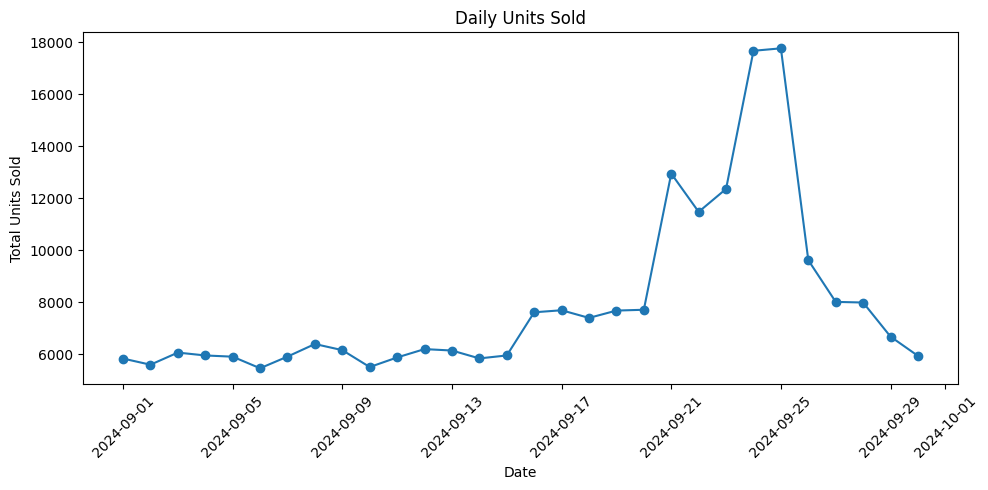

In [ ]:
import matplotlib.pyplot as plt

daily = sales.groupby("date")["total_units"].sum()

plt.figure(figsize=(10, 5))
plt.plot(daily.index, daily.values, marker="o")

plt.title("Daily Units Sold")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 6 — Self-check

**TODO:** fill in the real values. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [ ]:
progress = {
    'rows_after_cleaning': len(sales),        # TODO: an integer
    'decisions_logged': len(DECISIONS),           # TODO: how many entries in your log
    'canonical_products': tx['cleanSku'].nunique(),         # TODO: distinct products after consolidation
    'weather_api_rows': len(weather),           # TODO: rows returned by your API call
    'repo_url': 'https://github.com/rushilnanga/walmart-hurricane-project',
    'notebook_runs_clean': True,       # TODO: True after Restart and Run All
}

def check(items):
    ok = True
    for label, value in items.items():
        good = not (value is None or value is False
                    or (isinstance(value, str) and value.startswith('TODO')))
        print('PASS' if good else 'FAIL', '-', label, '=', value)
        ok = ok and good
    print()
    print('checkpoint complete:', ok)
    return ok

check(progress)

PASS - rows_after_cleaning = 3600
PASS - decisions_logged = 13
PASS - canonical_products = 37
PASS - weather_api_rows = 1
PASS - repo_url = https://github.com/rushilnanga/walmart-hurricane-project
PASS - notebook_runs_clean = True

checkpoint complete: True


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** We have only grouped 4/17 product types under 1 SKU, and we cannot answer question 2 until the rest are done.

**Plan, with an owner and a date:As a group, we plan to meet up this week and divide the rest of the assignment on Thursday.

### 8 — Where each question stands

**TODO:** mark each of the five questions. Use the owners from your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | in progress  | Jackson |
| Q2 SKU consolidation | in progress| Luke |
| Q3 weather correlation | in progress | Rushil |
| Q4 store and geography | not yet started | Derek |
| Q5 signal or artifact | not yet started| Derek |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.